# Generalized Spatial Regression with Partial Differential Equation Regularization

fdaPDE Team, MOX, Department of Mathematics, Politecnico di Milano, Italy

`fdaPDE` (Palummo et al., 2025) is a C++ library with an interface to R for *physics-informed spatial and functional data analysis*, at the intersection of statistics and numerical analysis. The library provides advanced statistical methods designed for data located over complex spatial domains, ranging from irregular planar regions and curved surfaces to linear networks and volumes, possibly evolving over time. The class of methods implemented in `fdaPDE` features regularization terms based on Partial Differential Equations (PDEs), which allow incorporating information derived from the physics of the problem under study into the statistical modeling. This makes `fdaPDE` an extremely flexible tool for the analysis of complex data. For a review of this class of methods, refer to @sangalli2021spatial.

`fdaPDE` offers a wide range of modeling capabilities -- including regression, nonparametric
density estimation, functional data analysis, and more -- for data located over a spatial domain,
possibly evolving over time. Among the broad range of modeling capabilities offered by `fdaPDE`, we focus here on the **generalized spatial regression method**.

## Model

Let $\mathcal{D} \subset \mathbb{R}^d\,,$ with $d \geq 1\,,$ be a bounded *spatial domain* of interest in which $n$ fixed *measurement stations* are located. Here, we consider $d = 2\,,$ but the proposed method can handle multidimensional spatial domains with complex shapes, including *two-dimensional curved surfaces* [@ettinger2016spatial] and *non-convex three-dimensional volumes* [@arnone2023analyzing]. At the location $\mathbf{p}_i = (p_{1i}, p_{2i})^\top \in \mathcal{D}$ of each station, we observe a realization $y_i \in \mathbb{R}$ of the response variable $Y_i$ under study, along with a set of covariates $\mathbf{x}_i = \left( x_{i,1},\ldots,x_{i,q} \right)^\top \in \mathbb{R}^q\,,$ if available. Specifically, we assume that $Y_i$ follows a distribution from the exponential family, with mean $\mu_i$ and a common scale parameter $\phi\,,$ for $i = 1, \ldots, n\,.$ In the context of spatial regression, we present a **generalized additive model** with Partial Differential Equation (PDE) regularization, which we formulate according to @wilhelm2016generalized, as follows:
$$g(\mu_i) = \theta_i = \mathbf{x}_i^\top \boldsymbol{\beta} + f(\mathbf{p}_i) \,, \qquad i = 1, \ldots, n,$$
where:

- $g$ is a continuously differentiable and strictly monotone **canonical link function**, whereas $\theta_i = \theta_i(\boldsymbol{\beta}, f)$ is referred to as the $i$th **canonical parameter**;

- $\boldsymbol{\beta} \in \mathbb{R}^q$ is the vector of **unknown regression coefficients** capturing the mean effects of the covariates;

- $f(\mathbf{p}_i) \in \mathbb{R}$ is the **unknown deterministic spatial field** $f : \mathcal{D} \to \mathbb{R}$ at the $i$th data location.

To estimate the unknown parameters, we refer to the basic form of the regularized methods, as reviewed in @sangalli2021spatial and originally introduced in @sangalli2013spatial. These works propose to maximize the following penalized functional based on the log-likelihood $\ell(\cdot ; \boldsymbol{\theta})$ for the considered distribution:
$$\sum_{i = 1}^n \ell\left( y_i; \theta_i \right) - R(f; \lambda)\,,$$
where $R(f; \lambda)$ is the **regularization term** that depends on the **smoothing parameter** $\lambda \in \mathbb{R}^+\,.$ The regularization term is defined using PDEs, with differential operators encoding the smoothness of $f$ over $\mathcal{D}\,.$ This term may also incorporate problem-specific information into the modeling framework, whenever available. The functional above embodies the trade-off between *data fidelity* and *model fidelity* through the least-squares term and the misfit with respect to the PDE, respectively. The balance between these two contributions is governed by the smoothing parameter. When the considered distribution is Gaussian, the optimization of the functional above coincides with the one that follows from the basic form of spatial regression with PDE regularization.

In its basic form, the regularization term is given by:
$$R(f; \lambda) = \lambda \int_\mathcal{D} \left( \Delta f (\mathbf{p}) \right)^2 \, \text{d}\mathbf{p}\,,$$
where the Laplacian operator is defined as
$$\Delta f = \frac{\partial^2 f}{\partial p_1^2} + \frac{\partial^2 f}{\partial p_2^2}$$
and is a measure of the local curvature of the field $f\,.$ More complex roughness penalties may be considered in the regularization term, with the PDE modeling the spatial variation of the unknown spatial field $f\,,$ thereby accounting for spatial non-stationarities and anisotropies, as discussed in @wilhelm2016generalized.

The method for Generalized Spatial Regression with Partial Differential Equation regularization presented in this vignette, hereafter referred to as `GSR-PDE`, is implemented within the newest version of the `fdaPDE` C++ library (Palummo et al., 2025). We load the library in the working environment as follows:

In [1]:
# Google Colab setup. Skip this cell when running locally.
if (any(nzchar(Sys.getenv(c(
  "COLAB_RELEASE_TAG",
  "COLAB_BACKEND_VERSION"
))))) {

  # Download the repository.
  repository <- "/content/course-materials"

  if (!dir.exists(repository)) {
    stopifnot(system2(
      "git",
      c(
        "clone", "--depth", "1",
        "https://github.com/fdaPDE/course-materials.git",
        shQuote(repository)
      )
    ) == 0L)
  }

  # Set the working directory and configure dependencies.
  setwd(file.path(
    repository,
    "courses",
    "[2026-Lancaster]-Physics-Informed-Statistical-Learning-for-Spatial-and-Functional-Data",
    "R", "notebook"
  ))

  source("../utils/colab_setup.R")
}

In [2]:
rm(list = ls())

# Import the fdaPDE library
# Load additional libraries and helper functions for plotting
suppressPackageStartupMessages({
    library(fdaPDE2)
    source("../utils/graphics.R")
  })

In [3]:
theme_set(theme_minimal() +
  theme(
    axis.title = element_text(),
    axis.text = element_text(),
    axis.ticks = element_line(),
    panel.grid = element_line()
  )
)

## Application to fire count data in Southern Italy

As a benchmark application in environmental sciences, we consider *fire count data* recorded in Southern Italy, during 2021. In addition to fire counts per administrative division (province), the dataset also includes several *areal covariates*, such as area, elevation, average temperature, solar radiation, total precipitation, population, land use, and land cover, as of 2021. The dataset is freely and publicly available by different data sources, including the [Fire Information for Resource Management System (FIRMS)](https://firms.modaps.eosdis.nasa.gov) of the National Aeronautics and Space Administration (NASA), the [CORINE Land Cover (CLC)](https://land.copernicus.eu/en) from the European Environment Agency (EEA), the [Digital Elevation Model (DEM)](https://tinitaly.pi.ingv.it/Download_Area1_1.html) from the National Institute of Geophysics and Volcanology (INGV), and the [Copernicus ERA5](https://cds.climate.copernicus.eu/cdsapp#!/dataset/reanalysis-era5-land?tab=overview) from the European Centre for Medium-Range Weather Forecasts (ECMWF) as part of the Copernicus Climate Change Service (C3S). Due to ongoing climate change and global warming, large-scale wildfires are occurring with increasing frequency worldwide, especially in southern Europe. This results in severe repercussions and damage to ecosystems, infrastructures, material assets, and socio-economic activities. Therefore, an in-depth statistical analysis of this phenomenon is becoming crucial for driving the implementation of new policies aimed at preserving both artificial and natural environments.

### 1. Spatial domain
We import the preprocessed data observed in Southern Italy during 2021 from the shapefile `../../data/GSRPDE_2D/GSRPDE_2D_data.shp` as a `sf` [@pebesma2025sf] object.

In [4]:
## [DATA]
# Load the data
data_sf <- st_read(dsn = "../../data/GSRPDE_2D/GSRPDE_2D_data.shp", quiet = TRUE)
head(data_sf)

# Number of data (i.e., of provinces)
n <- nrow(data_sf)

,COUNTRY,REGION,PROVINCE,TERRITORY,AREA,MIN_ELEV,AVG_ELEV,MAX_ELEV,ARTIFIC,AGRICUL,FOREST,WETLANDS,WATER,FIRE_COUNT,POP,REF_AREA,POP_DENS,geometry
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<MULTIPOLYGON [°]>
1,Italy,Sicilia,Agrigento,Island,3025.283,0.5303,310.0765,1414.2872,0.0360,0.7901,0.1641,0.0002,0.0096,306,413177,3052.82,135.3427,MULTIPOLYGON (((12.89625 37...
2,Italy,Campania,Avellino,South,2803.711,92.7902,610.1539,1695.8716,0.0445,0.6325,0.3213,0.0002,0.0015,16,398932,2805.96,142.1731,MULTIPOLYGON (((14.60641 40...
3,Italy,Puglia,Bari,South,3797.713,1.0050,302.0524,659.2282,0.0633,0.8279,0.1074,0.0000,0.0014,75,1225048,3862.66,317.1514,MULTIPOLYGON (((17.35441 40...
4,Italy,Puglia,Barletta-Andria-Trani,South,1524.347,0.4824,217.2597,657.4872,0.0448,0.8197,0.1005,0.0303,0.0047,26,379509,1542.99,245.9569,MULTIPOLYGON (((16.20329 40...
5,Italy,Campania,Benevento,South,2045.429,33.2261,479.9234,1719.1609,0.0371,0.7076,0.2527,0.0000,0.0026,17,263125,2080.37,126.4799,MULTIPOLYGON (((14.5728 41....
6,Italy,Puglia,Brindisi,South,1822.502,0.4948,109.3009,394.1095,0.0658,0.9121,0.0153,0.0018,0.0050,24,379522,1861.33,203.8983,MULTIPOLYGON (((18.09681 40...


Before discussing the data in detail, we visualize the boundaries of each province within the spatial domain of interest in Southern Italy. These boundaries are already embedded in the `sf` object loaded above. To enable interactive visualization, we use the `mapview` [@appelhans2025mapview] R package.

In [5]:
## [SPATIAL DOMAIN]
# Provinces
provinces_sfc <- st_geometry(obj = data_sf)
provinces_sf <- st_as_sf(x = provinces_sfc)

# Boundaries of each province
boundary_sf <- st_boundary(x = provinces_sf)

# Interactive plot
display_map(
    mapview(provinces_sf, col.regions = "gray75", lwd = 1.5,
        legend = FALSE, layer.name = "provinces")
)

Warning message in cbind(`Feature ID` = fid, mat):
“number of rows of result is not a multiple of vector length (arg 1)”


<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 1: Boundaries of each of the 33 provinces in Southern Italy.
</div>

Now we build a **regular mesh** of the spatial domain above. The mesh provides a discretization of the spatial domain, which is required to solve the estimation problem using the finite element method. To do so, we directly load mesh nodes and triangles from `../../data/GSRPDE_2D/nodes.txt` and `../../data/GSRPDE_2D/cells.txt` files. These files store a matrix of size \#nodes-by-2 containing the $x$ and $y$ coordinates of the mesh nodes, and a matrix of size \#triangles-by-3, where the $i$th row contains the indices of the mesh nodes forming the $i$th triangle. These matrices are obtained using the `femR` [@clemente2025femr] and `RTriangle` [@shewchuk2025RTriangle] R packages; further details are omitted here. Other software can be used to get the triangulation; for example, it can be constructed through the `fmesher` [@lindgren2025fmesher] R package.

In [6]:
## [MESH]
# Load the mesh nodes
mesh_nodes <- read.table(file = "../../data/GSRPDE_2D/nodes.txt")

# Load the nodes markers
mesh_nodesmarkers <- read.table(file = "../../data/GSRPDE_2D/boundary.txt")

# Load the mesh triangles
mesh_triangles <- read.table(file = "../../data/GSRPDE_2D/cells.txt")

# Set up the triangulation for fdaPDE
mesh <- triangulation(
    cells    = mesh_triangles,
    nodes    = mesh_nodes,
    boundary = mesh_nodesmarkers
)

We visualize the resulting mesh of the spatial domain of interest.

In [7]:
# Interactive plot
display_map(
    mapview(boundary_sf,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
        legend = FALSE, layer.name = "domain") +
    mapview(mesh, crs = 4326, col.regions = "transparent", lwd = 1.25,
          legend = FALSE, layer.name = "mesh")
)

Warning message in cbind(`Feature ID` = fid, mat):
“number of rows of result is not a multiple of vector length (arg 1)”


<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 2: Regular mesh of the spatial domain of interest of Southern Italy with $2\,563$ nodes and $4\,514$ triangles. Note that the mesh conforms to the boundaries of the provinces.
</div>

We use the triangulation just created to define the spatial support of a `geoframe` object. This object will host layers containing data observed over the spatial support.

In [8]:
# Create the geoframe
italy <- geoframe(domain = mesh)
italy

Geoframe with 0 layers
Bounding box:    xmin: 12.44208 ymin: 36.64986 xmax: 18.52069 ymax: 42.89375
Number of nodes: 2563
Number of cells: 4514


### 2. Data

We briefly introduce the data under study. We add a data layer to the `geoframe` object defined above, thus obtaining a format compatible with the implementation of the proposed regression method.

In [9]:
## [DATA]
# Add layer with data to the geoframe object (directly from the shapefile)
italy$load_shp(layer = "fires", filename = "../../data/GSRPDE_2D/GSRPDE_2D_data.shp")
italy

Geoframe with 1 layers
Bounding box:    xmin: 12.44208 ymin: 36.64986 xmax: 18.52069 ymax: 42.89375
Number of nodes: 2563
Number of cells: 4514

Layer: fires
Type:  AREAL
Dims: 33, 17
First 6 data rows:
COUNTRY REGION   PROVINCE              TERRITORY AREA    MIN_ELEV AVG_ELEV MAX_ELEV ARTIFIC AGRICUL FOREST  WETLANDS WATER   FIRE_COUNT POP     REF_AREA POP_DENS 
<chr>   <chr>    <chr>                 <chr>     <flt64> <flt64>  <flt64>  <flt64>  <flt64> <flt64> <flt64> <flt64>  <flt64> <flt64>    <flt64> <flt64>  <flt64>  
Italy   Sicilia  Agrigento             Island    3025.28 0.5303   310.076  1414.29  0.036   0.7901  0.1641  2e-04    0.0096  306        413177  3052.82  135.343  
Italy   Campania Avellino              South     2803.71 92.7902  610.154  1695.87  0.0445  0.6325  0.3213  2e-04    0.0015  16         398932  2805.96  142.173  
Italy   Puglia   Bari                  South     3797.71 1.005    302.052  659.228  0.0633  0.8279  0.1074  0        0.0014  75         1225048 3

In [10]:
# Variable names
names(italy[["fires"]])

# Number of variables
cat("Number of variables:", ncol(italy[["fires"]]))

[1] "COUNTRY"    "REGION"     "PROVINCE"   "TERRITORY"  "AREA"      
 [6] "MIN_ELEV"   "AVG_ELEV"   "MAX_ELEV"   "ARTIFIC"    "AGRICUL"   
[11] "FOREST"     "WETLANDS"   "WATER"      "FIRE_COUNT" "POP"       
[16] "REF_AREA"   "POP_DENS"

Number of variables: 17

The variables observed at the province level are given by:

- "COUNTRY", "REGION", "PROVINCE": names of the country, region, and province;

- "TERRITORY": type of territory ("South", "Island");

- "AREA": area (in $\text{km}^2$);

- "MIN_ELEV", "AVG_ELEV", "MAX_ELEV": minimum, average, and maximum elevation (in $\text{m}$);

- "ARTIFIC", "AGRICUL", "FOREST", "WETLANDS", "WATER": percentages of artificial areas, agricultural areas, forest and seminatural areas, wetlands, and water bodies;

- "FIRE_COUNT": number of fires recorded in 2021;

- "POP", "REF_AREA", "POP_DENS": population, reference area, and population density.

In addition, "geometry" contains the multipolygons defining the provinces under study.

The values of most of these variables, recorded by province in 2021, are shown in the interactive plot below, created using `mapview`.

In [11]:
# Color palettes
color_palette_fire_counts <- c("#FFFFB2", "#FECC5C", "#FD8D3C", "#F03B20", "#BD0026")
color_palette_population  <- c("#DEEBF7", "#9ECAE1", "#6BAED6", "#3182BD", "#08519C")
color_palette_forest      <- c("#E5F5E0", "#A1D99B", "#74C476", "#31A354", "#006D2C")
color_palette_elevation   <- c("#006400", "#A2CD5A", "#F5DEB3", "#8B864E", "#8B2323")

# Interactive plot
display_map(
    mapview(italy[["fires"]], crs = 4326, varnames = c("FIRE_COUNT", "POP", "FOREST", "AVG_ELEV"),
        color_palettes = list(color_palette_fire_counts,
                              color_palette_population,
                              color_palette_forest,
                              color_palette_elevation))
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 3: Fire counts observed at 33 provinces in Southern Italy during 2021 (top left); population measured at the province level as of 2021 (top right); forest and seminatural areas (in $\text{km}^2$) measured at the province level as of 2021 (bottom left); average elevation (in $\text{m}$) measured at the province level as of 2021 (bottom right).
</div>

First, we focus on the FIRE_COUNT variable. The *non-standard shape* of the spatial domain strongly influences the quantity under study. For example, fire counts recorded in the two provinces facing the Strait of Messina, namely the provinces of Messina in Sicily and Reggio-Calabria in Calabria, are not highly correlated. This spatial variation suggests that fire counts depends on factors beyond purely environmental ones (e.g., temperature, elevation, land cover), which typically vary smoothly across space. Specifically, differences in fire counts may be partly due to the varying number of arson incidents reported in 2021 in the two provinces, highlighting the role of unobserved cultural and social phenomena, which may not be fully captured by methods that rely solely on Euclidean distances. Differently, `GSR-PDE` naturally accounts for the geometry of the domain, which may feature disjoint regions with irregular boundaries and concavities, as in the case under consideration.

### 3. GSR-PDE model fitting for Poisson response (without covariates)

We are ready to perform the `GSR-PDE` spatial regression method using the `gsr` function. This function offers several options for solving the regression problem, including the possibility to specify covariates, PDE parameters, and boundary conditions, whenever available. The `gsr` function supports several distributions within the exponential family for generalized linear models and can handle areal data, as in the case under study. In addition, the function implements different algorithms for degrees of freedom computation and criteria for optimal smoothing parameter selection. For further information, see the documentation by typing `?gsr`.

#### 3.1 Isotropic smoothing with optimal smoothing parameter via Generalized Cross-Validation (GCV) minimization using grid search method

Here, in its simplest form, we apply a penalized Poisson regression without covariates and with isotropic smoothing to the areal fire count data, which corresponds to incorporating the Laplace operator in the regularization term. Specifically, we assume that each response variable $Y_i$ is Poisson-distributed with mean $\mu_i\,,$ for $i = 1,\ldots,n\,,$ with $n = 33$ being the number of provinces in the dataset. We consider the following model:
$$\log(\mu_i) = \theta_i = f(\mathbf{p}_i) \,, \qquad i = 1, \ldots, n\,.$$
This can be achieved by specifying the option `family = poisson` as a parameter of the `gsr` function. We select the optimal value for the smoothing parameter $\lambda$ by minimizing the **Generalized Cross-Validation** (GCV) index on a finite grid of proposed values. To this end, we perform a stochastic computation of the degrees of freedom.

In [12]:
## [ISOTROPIC SMOOTHING WITH OPTIMAL SMOOTHING PARAMETER]
# Set up the finite element function (order 1)
f_grid <- fe_function(mesh, type = "P1")

# Proposed values for the smoothing parameter
lambda_grid <- 10^seq(from = -6, to = 0, by = 0.25)

# Isotropic smoothing model
model_grid <- gsr(formula = FIRE_COUNT ~ f_grid, data = italy, family = "poisson")

# Isotropic smoothing fit with fixed lambda
fit_grid <- model_grid$fit(
  calibrator = gcv(
    optimizer = grid_search(lambda_grid)
  )
)

We print the regression model outputs.

In [13]:
# Fitted values at mesh nodes
cat("Fitted values at mesh nodes:", head(f_grid$coeff), "\n")

# Fitted values at locations
cat("Fitted values at locations:", head(model_grid$fitted), "\n")

# Residuals at locations: response - fitted values
cat("Residuals statistics\n")
grid_residuals <- c(italy[["fires"]]$FIRE_COUNT - model_grid$fitted)
summary(grid_residuals)

Fitted values at mesh nodes: 4.860979 4.896364 5.041834 5.091835 5.132971 5.166168 
Fitted values at locations: 5.849399 4.322543 4.284184 4.920359 4.128864 4.021816 
Residuals statistics


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  4.228  21.080  73.160 131.982 197.474 501.911 

Moreover, it is possible to inspect the behavior of the GCV indices as a function of the values proposed for the smoothing parameter $\lambda\,.$

[1] 0.03162278

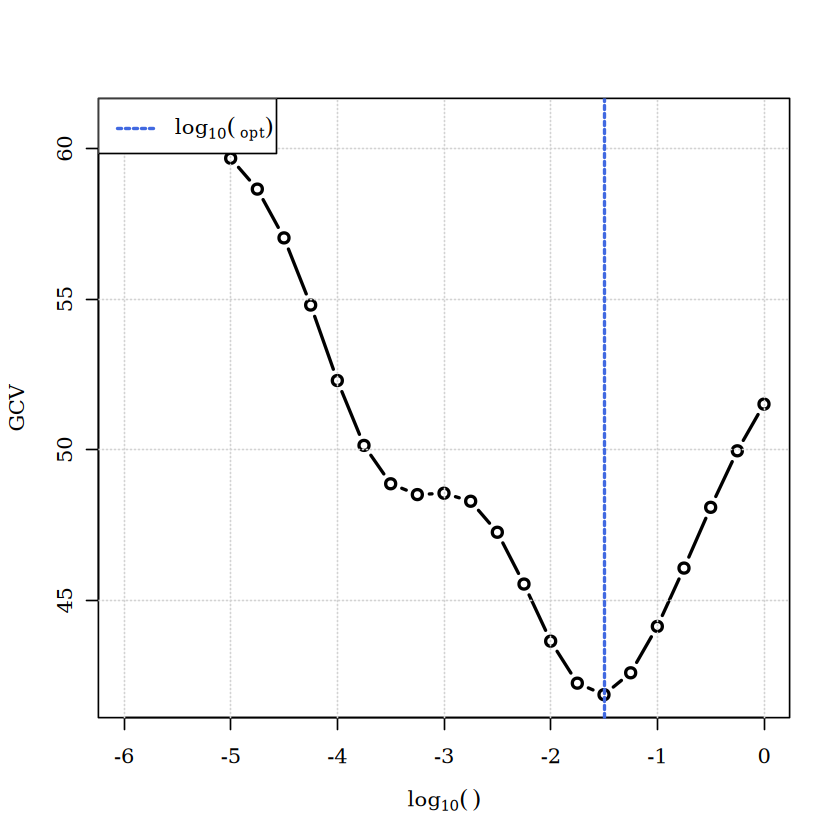

In [14]:
# Optimal value selected for the smoothing parameter
lambda_opt_grid <- fit_grid$optimum
lambda_opt_grid

# Plot of the GCV curve
par(family = "serif")
plot(x = log10(lambda_grid), y = fit_grid$values, type = 'b', lwd = 2, xlab = TeX("$\\log_{10}(\\lambda)$"), ylab = "GCV")
grid()
abline(v = log10(lambda_opt_grid), lty = 2, lwd = 2, col = "royalblue")
legend("topleft", lty = 2, lwd = 2, col = "royalblue", legend = TeX("$\\log_{10}(\\lambda_{opt})"))

<div style="text-align: center;">
Figure 4: GCV curve.
</div>

The GCV curve is convex with minimum realized at the optimal value selected by the method -- specifically, $0.03162278\,.$

The regression model fit over the provinces of interest is displayed below (left). For qualitative comparison, the fire count data is also displayed (right).

In [15]:
# Compute areal estimate by province
f_grid_areal <- eval_areal(x = f_grid, layer = italy[["fires"]], crs = 4326)

# Interactive plot
map1 <- mapview(f_grid_areal, 
          col.regions = color_palette_fire_counts,
          na.color = "transparent", layer.name = "ESTIMATE") +
        mapview(boundary_sf,
          col.regions = "transparent", alpha.regions = 0.25, col = "black", lwd = 1.5,
          legend = FALSE, layer.name = "domain")

map2 <- mapview(italy[["fires"]], 
          crs = 4326, varnames = "FIRE_COUNT",
          color_palettes = list(color_palette_fire_counts)) +
        mapview(boundary_sf,
          col.regions = "transparent", alpha.regions = 0.25, col = "black", lwd = 1.5,
          legend = FALSE, layer.name = "domain")

display_map(sync(map1, map2))

Warning message:
“Found less unique colors (5) than unique zcol values (33)! 
Interpolating color vector to match number of zcol values.”
Warning message in cbind(`Feature ID` = fid, mat):
“number of rows of result is not a multiple of vector length (arg 1)”
Warning message in cbind(`Feature ID` = fid, mat):
“number of rows of result is not a multiple of vector length (arg 1)”


<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 5: Estimated spatial field of the fire counts provided by the isotropic `GSR-PDE` for each province without covariates and with $\lambda$ selected via GCV minimization using grid search method (left); fire counts observed at 33 provinces in Southern Italy during 2021 (right). We recall that the latter are not used for estimation purposes; they are displayed here solely to allow comparison with the fire counts estimate computed by the proposed `GSR-PDE` method based on the observations loaded above.
</div>

The smoothing fit already appears very accurate.

#### 3.2 Poisson regression and intensity estimation

We show the pointwise spatial prediction. To evaluate the regression model fit over a fine grid and enable interactive visualization of the estimate, we internally create a new `raster` object. Then we compute the fitted values over the grid using the `$eval` method. We plot the resulting estimate with `mapview`: this is just one possibility; various other plotting options are available depending on the specific purpose.

The regression model fit over the fine grid is displayed below (left). In addition, we load and show the point pattern associated with the locations of fires occurred in 2021 (right).

Warning message in cbind(`Feature ID` = fid, mat):
“number of rows of result is not a multiple of vector length (arg 1)”
Warning message in cbind(`Feature ID` = fid, mat):
“number of rows of result is not a multiple of vector length (arg 1)”


<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
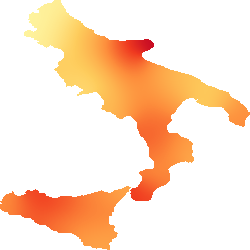

In [16]:
# Load locations of fires
locations <- st_read(dsn = "../../data/GSRPDE_2D/GSRPDE_2D_locations.shp", quiet = TRUE)

# Interactive plot
map1 <- mapview(f_grid, 
          crs = 4326, col.regions = color_palette_fire_counts,
          alpha.regions = 0.75, na.color = "transparent",
          layer.name = "intensity") +
        mapview(boundary_sf, 
          color = "gray25", lwd = 1.5,
          legend = FALSE, layer.name = "provinces")

map2 <- mapview(locations, 
          legend = FALSE, col.regions = "black",
          alpha.regions = 0.75, stroke = FALSE, cex = 2,
          layer.name = "locations") +
        mapview(boundary_sf, color = "gray25", lwd = 1.5,
          legend = FALSE, layer.name = "provinces")

display_map(sync(map1, map2))

<div style="text-align: center;">
Figure 6: Estimated spatial field of the fire counts provided by the isotropic `GSR-PDE` without covariates and with $\lambda$ selected via GCV minimization using grid search method (left); locations of fires occurred in Southern Italy in 2021 (right).
</div>

In particular, by focusing on the spatial point pattern rather than aggregated counts, the Poisson regression and the inhomogeneous Poisson point process share equivalent modeling structures, enabling a direct comparison of their pointwise intensity estimates. For density and intensity estimation with PDE regularization, see @ferraccioli2021nonparametric and @begu2024nonparametric.

### 4. Future developments

The phenomenon under study is influenced by several factors, including the average elevation, the population, the type of territory, as well as the extent of artificial areas, agricultural areas, forest and seminatural areas, wetlands and water bodies, all measured at the province level as of 2021. These covariates could be incorporated into the `GSR-PDE` modeling framework to better explain fire count data in Southern Italy.

Moreover, as a future development, the model fitting could leverage problem-specific information derived from the physics of the underlying factors influencing the phenomenon considered here. In particular, the regularization term could incorporate a PDE accounting for the presence of wind across the provinces.

## References

<div id="refs" class="references csl-bib-body hanging-indent"
data-entry-spacing="0" data-line-spacing="2" role="list">
<div id="ref-appelhans2025mapview" class="csl-entry" role="listitem">
Appelhans, T., Detsch, F., Reudenbach, C., &amp; Woellauer, S. (2023).
<em>Mapview: <span>I</span>nteractive viewing of spatial data in
<span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=mapview"
class="uri">https://CRAN.R-project.org/package=mapview</a>.
</div>
<div id="ref-arnone2023analyzing" class="csl-entry" role="listitem">
Arnone, E., Negri, L., Panzica, F., &amp; Sangalli, L. M. (2023).
Analyzing data in complicated 3D domains: Smoothing, semiparametric
regression, and functional principal component analysis.
<em>Biometrics</em>, <em>79</em>(4), 3510–3521. <a
href="https://doi.org/10.1111/biom.13845">https://doi.org/10.1111/biom.13845</a>
</div>
<div id="ref-begu2024nonparametric" class="csl-entry" role="listitem">
Begu, B., Panzeri, S., Arnone, E., Carey, M., &amp; Sangalli, L. M.
(2024). A nonparametric penalized likelihood approach to density
estimation of space-time point patterns. <em>Spatial Statistics</em>. <a
href="https://doi.org/10.1016/j.spasta.2024.100824">https://doi.org/10.1016/j.spasta.2024.100824</a>
</div>
<div id="ref-clemente2025femr" class="csl-entry" role="listitem">
Clemente, A., Palummo, A., Arnone, E., Formaggia, L., &amp; Sangalli, L.
M. (2025). <em>femR: <span>B</span>ridging physics and statistics in
<span>R</span></em>. url: <a href="https://github.com/fdaPDE/femR"
class="uri">https://github.com/fdaPDE/femR</a>.
</div>
<div id="ref-ettinger2016spatial" class="csl-entry" role="listitem">
Ettinger, B., Perotto, S., &amp; Sangalli, L. M. (2016). Spatial
regression models over two-dimensional manifolds. <em>Biometrika</em>,
<em>103</em>(1), 71–88.
</div>
<div id="ref-ferraccioli2021nonparametric" class="csl-entry"
role="listitem">
Ferraccioli, F., Arnone, E., Finos, L., Ramsay, J. O., &amp; Sangalli,
L. M. (2021). Nonparametric density estimation over complicated domains.
<em>Journal of the Royal Statistical Society Series B: Statistical
Methodology</em>, <em>83</em>(2), 346–368. <a
href="https://doi.org/10.1111/rssb.12415">https://doi.org/10.1111/rssb.12415</a>
</div>
<div id="ref-lindgren2025fmesher" class="csl-entry" role="listitem">
Lindgren, F. (2025). <em>Fmesher: <span>T</span>riangle meshes and
related geometry tools</em>. url: <a
href="https://CRAN.R-project.org/package=fmesher"
class="uri">https://CRAN.R-project.org/package=fmesher</a>.
</div>
<div id="ref-palummo2026fdapde" class="csl-entry" role="listitem">
Palummo, A., Clemente, A., Sangalli, E., Arnone, Formaggia, L., &amp;
Maria, L. (2025). <em>fdaPDE: <span>P</span>hysics-informed statistical
learning</em>. url: <a href="https://github.com/fdaPDE/fdaPDE-R"
class="uri">https://github.com/fdaPDE/fdaPDE-R</a>.
</div>
<div id="ref-pebesma2025sf" class="csl-entry" role="listitem">
Pebesma, E. (2025). <em>Sf: <span>S</span>imple <span>F</span>eatures
for <span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=sf"
class="uri">https://CRAN.R-project.org/package=sf</a>.
</div>
<div id="ref-sangalli2021spatial" class="csl-entry" role="listitem">
Sangalli, L. M. (2021). Spatial regression with partial differential
equation regularisation. <em>International Statistical Review</em>,
<em>89</em>(3), 505–531. <a
href="https://doi.org/10.1111/insr.12444">https://doi.org/10.1111/insr.12444</a>
</div>
<div id="ref-sangalli2013spatial" class="csl-entry" role="listitem">
Sangalli, L. M., Ramsay, J. O., &amp; Ramsay, T. O. (2013). Spatial
spline regression models. <em>Journal of the Royal Statistical Society
Series B: Statistical Methodology</em>, <em>75</em>(4), 681–703. <a
href="https://doi.org/10.1111/rssb.12009">https://doi.org/10.1111/rssb.12009</a>
</div>
<div id="ref-shewchuk2025RTriangle" class="csl-entry" role="listitem">
Shewchuk, J. R., &amp; Sterratt, D. C. (2025). <em>RTriangle - a
2<span>D</span> quality mesh generator and <span>D</span>elaunay
triangulator</em>. url: <a
href="https://CRAN.R-project.org/package=RTriangle"
class="uri">https://CRAN.R-project.org/package=RTriangle</a>.
</div>
<div id="ref-wilhelm2016generalized" class="csl-entry" role="listitem">
Wilhelm, M., &amp; Sangalli, L. M. (2016). Generalized spatial
regression with differential regularization. <em>Journal of Statistical
Computation and Simulation</em>, <em>86</em>(13), 2497–2518. <a
href="https://doi.org/10.1080/00949655.2016.1182532">https://doi.org/10.1080/00949655.2016.1182532</a>
</div>
</div>